# 04 · Búsqueda del segundo alelo oculto

> **Lugar en el argumento:** Track 1, explicación alternativa. Intenta encontrar la parte de
> un modelo bialélico que el filtro codificante podría haber dejado fuera.
>
> **Salida principal:** funnel del locus + predicciones regulatorias REF/ALT. Un negativo aquí
> se limita a SNV/indel en la ventana evaluada; no excluye SV/CNV.

> **Saneado:** sin coordenadas ni identidad de variantes. El locus se describe por tamaño y
> por posición relativa.

## Pregunta biológica

Si el análisis estándar encuentra **un solo** alelo claramente patogénico en un gen de MVA, el
segundo puede ser una variante **reguladora**, **intrónica profunda** o **estructural**.

**¿Existe un segundo alelo que nuestro pipeline codificante no ve?**

## Hipótesis y preregistro

`docs/DECISIONS.md` § *Hidden Second Allele*. Ventana: cuerpo del gen ± ~100 kb, porque **hay
precedente humano publicado** de un segundo alelo regulador decenas de kb aguas arriba;
restringirse al cuerpo del gen sería conceptualmente incorrecto.

Orden de matanza, del filtro barato al caro:
frecuencia poblacional, calidad de la llamada, posición funcional, conservación y
señal reguladora, y por último AlphaGenome

**La predicción #4 decía que AlphaGenome daría Δ plano, y se escribió queriendo fallarla**,
para que un negativo fuera reportable en vez de decepcionante.

### Integración visual · 24 septiembre 2026

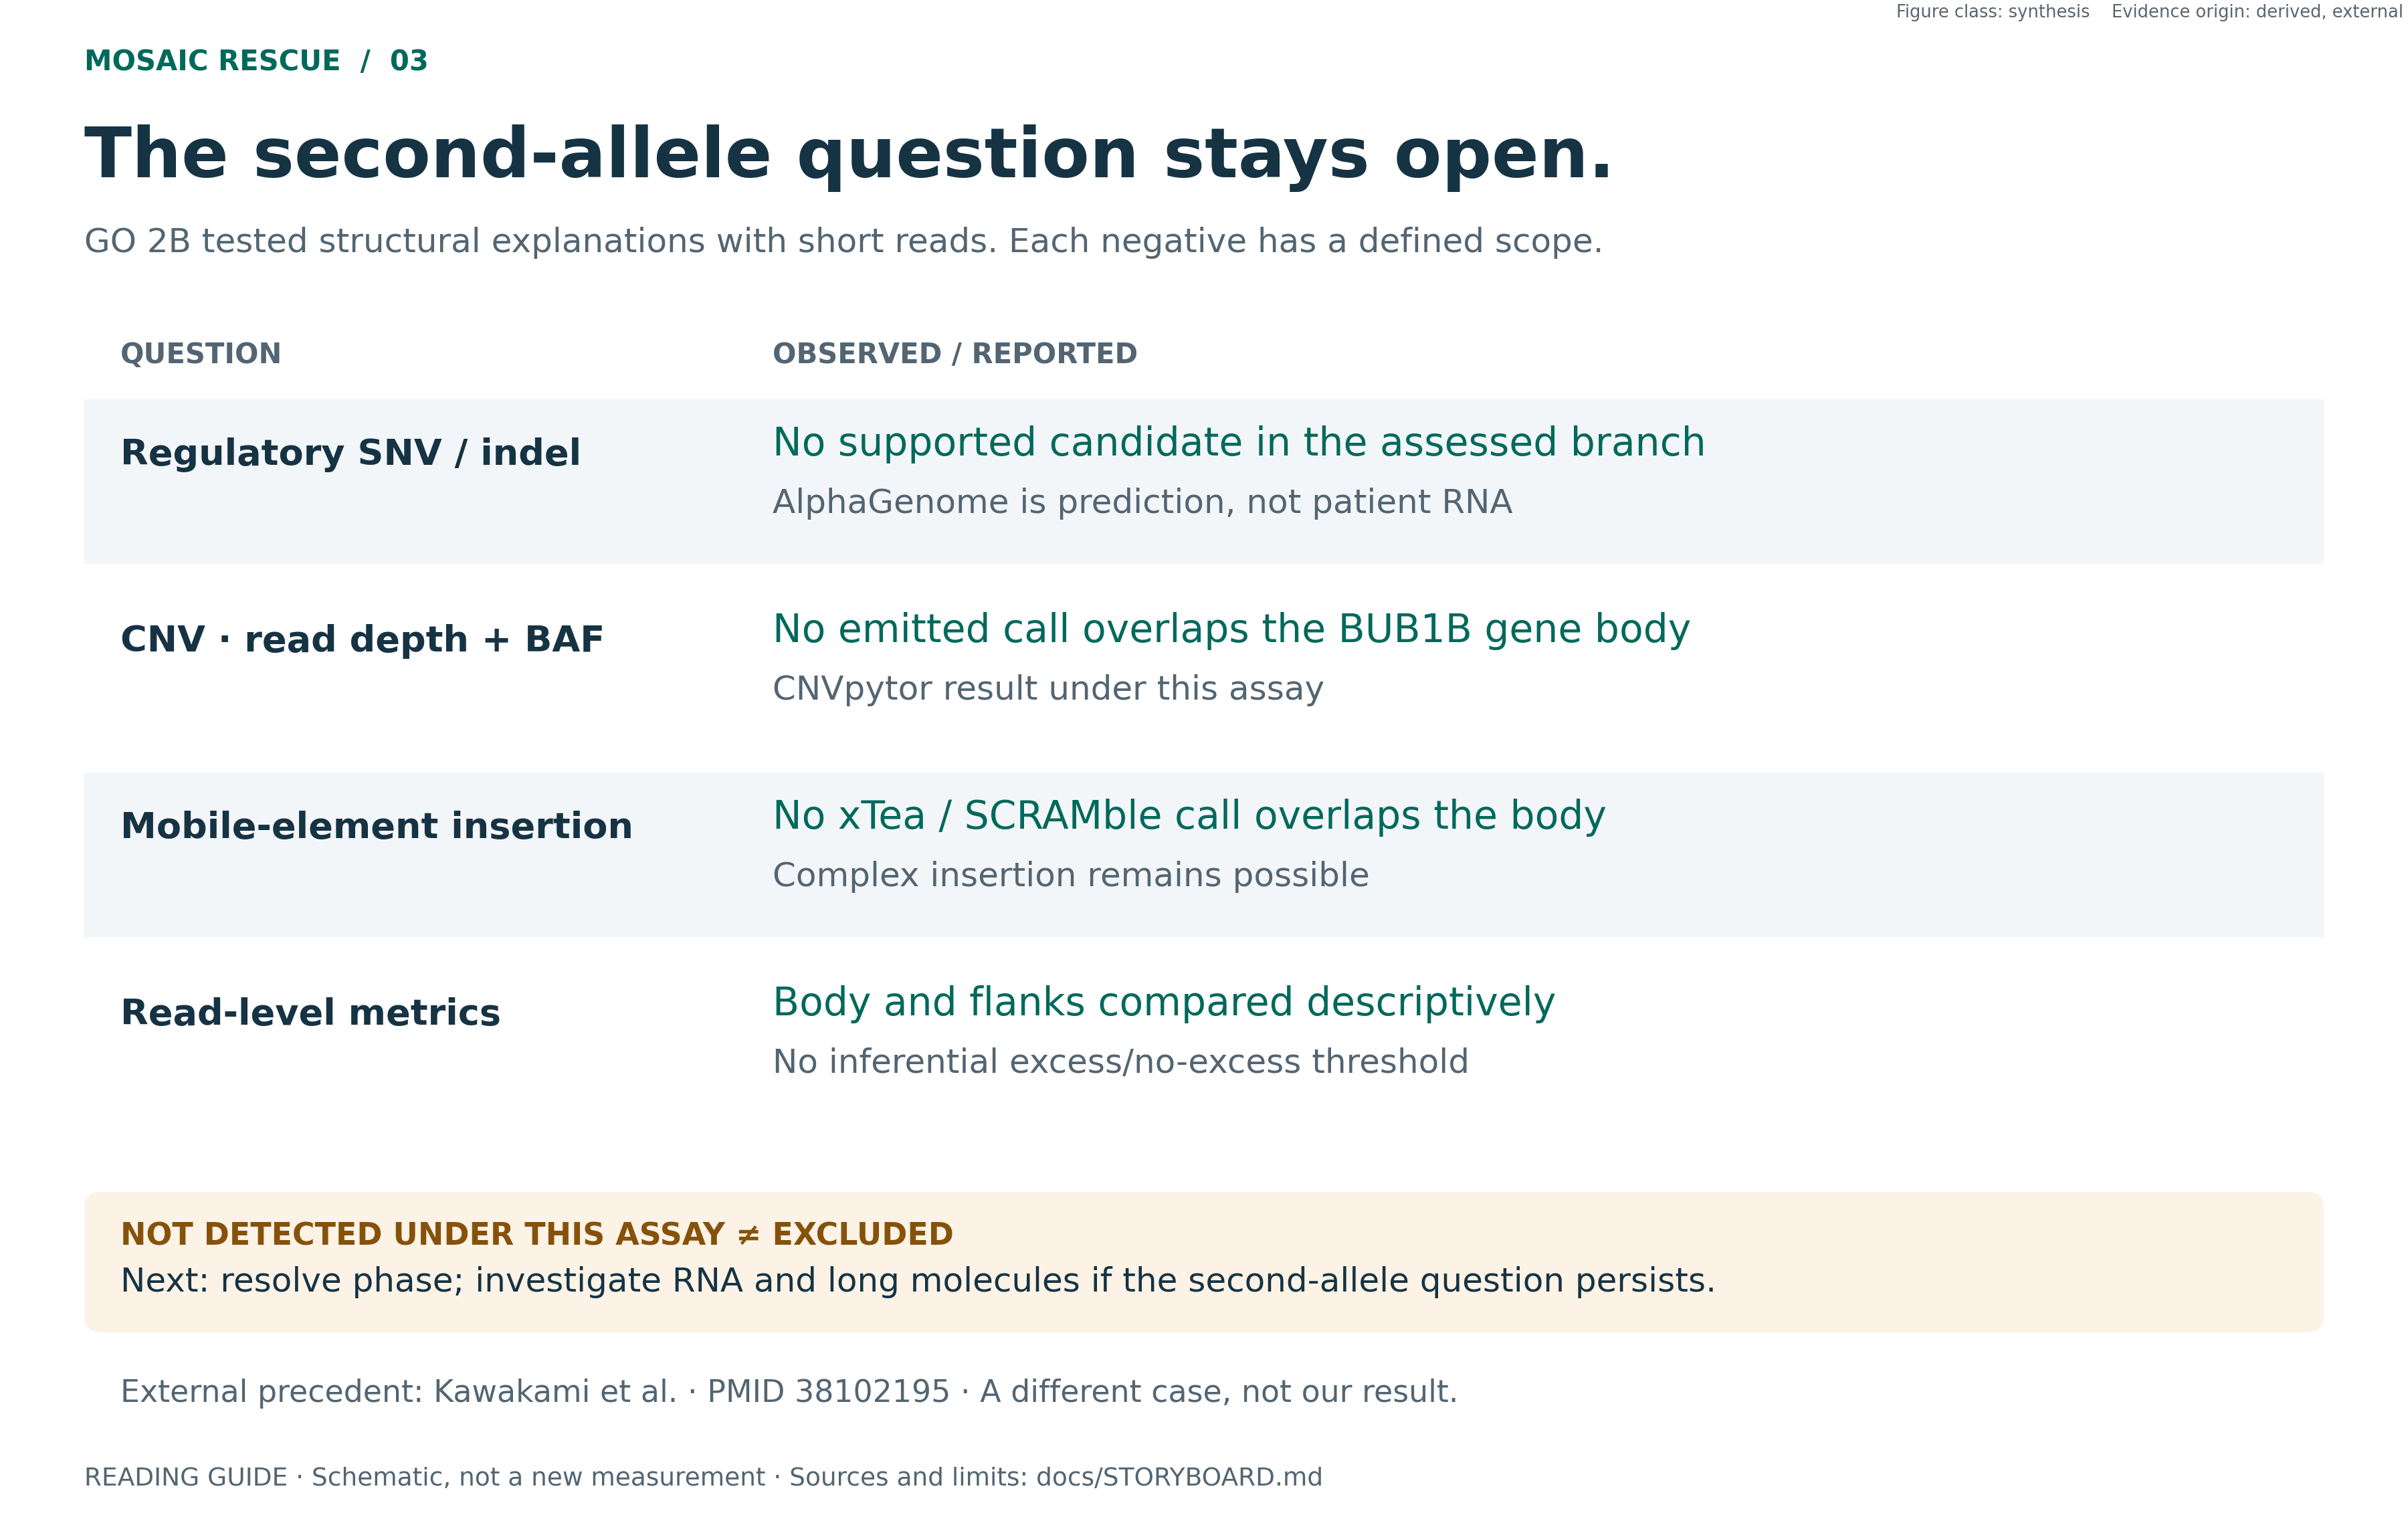

**SYNTHESIS · DERIVED / EXTERNAL.** Cierre GO 2B: sin llamada CNV RD+BAF o MEI solapante al cuerpo de BUB1B. Una inserción compleja no queda excluida.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

### Integración visual · 24 septiembre 2026

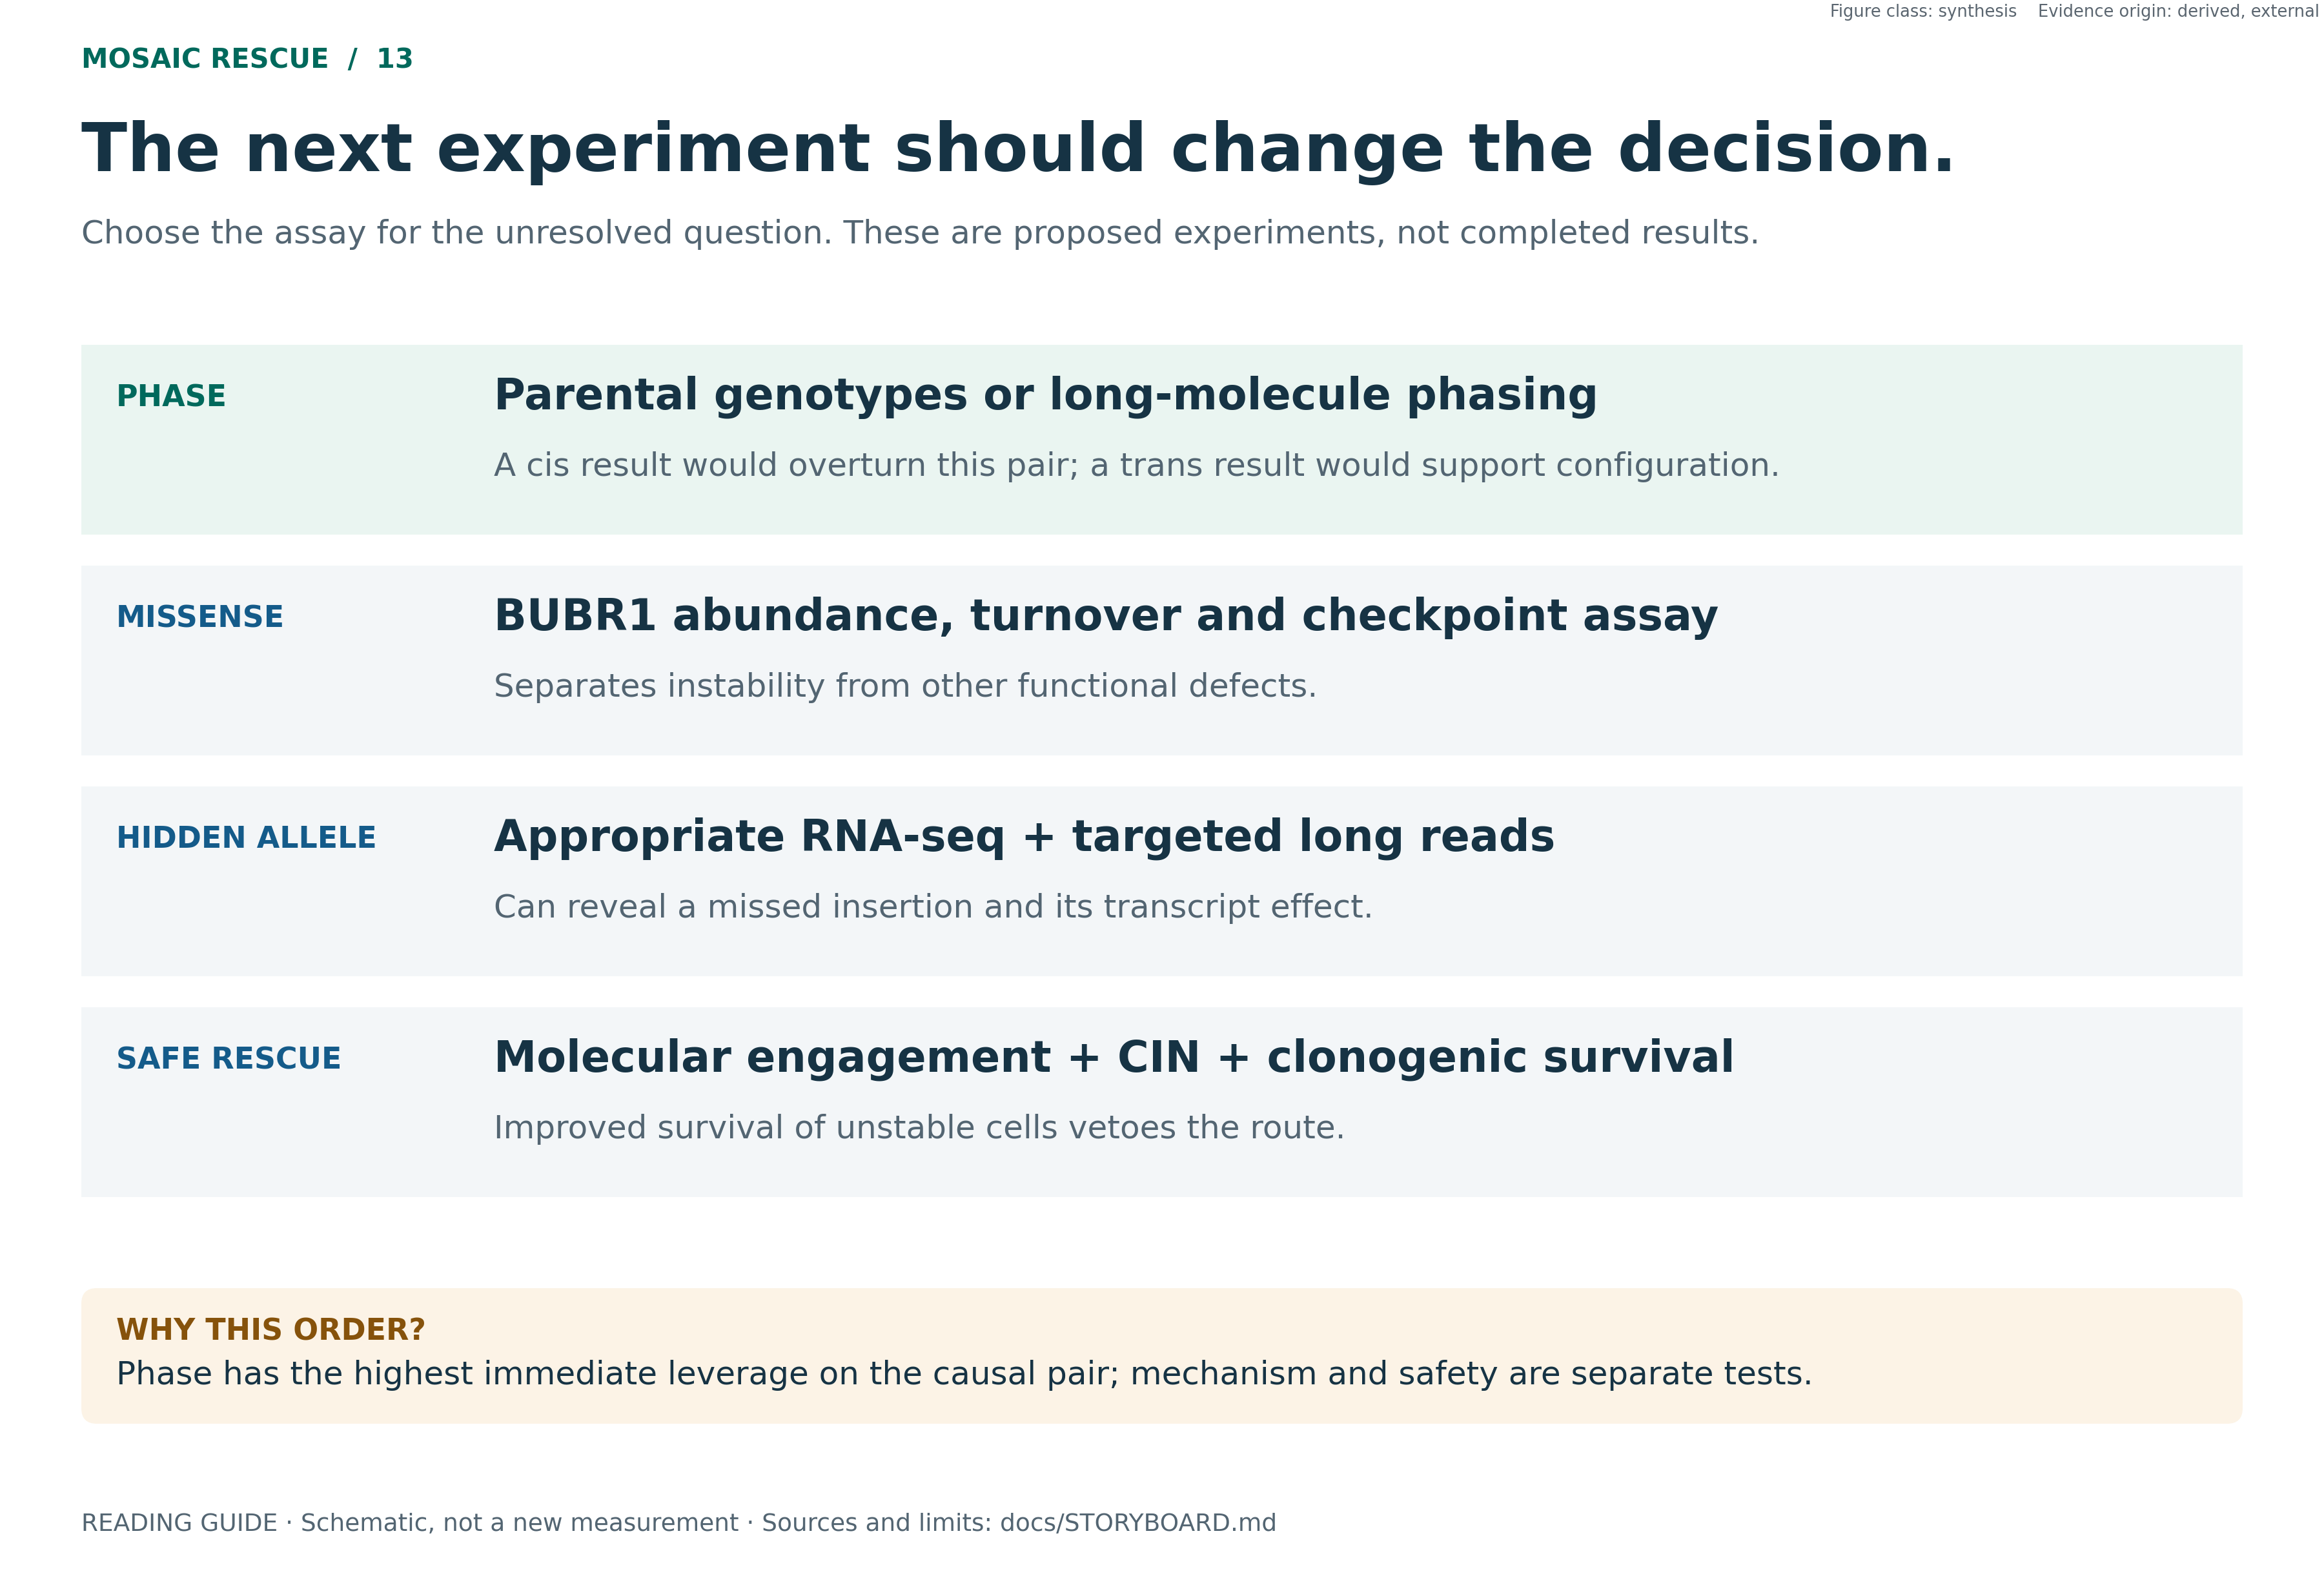

**SYNTHESIS · DERIVED / EXTERNAL.** RNA-seq y lecturas largas son propuestas. Las pistas AlphaGenome siguientes son predicciones existentes, no RNA medido ni calibración EXP-024 completada.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Que se observa", "Alcance del resultado")

## Método · el funnel del locus

In [3]:
LOCUS = [
    ("variantes en el locus ampliado (~270 kb)", 321),
    ("tras filtro de frecuencia poblacional",     4),
    ("raras y de calidad, posicion funcional",    1),
    ("enviadas a AlphaGenome",                    1),
    ("con delta relevante",                       0),
]
for n, v in LOCUS:
    print(f"  {n:<44}{v:>6}")
print()
print("  La prediccion #1 fallo por lo alto: se esperaban 800-2000 variantes y hubo 321.")
print("  Se registra como fallo de calibracion de la prediccion, no como resultado.")

  variantes en el locus ampliado (~270 kb)       321
  tras filtro de frecuencia poblacional            4
  raras y de calidad, posicion funcional           1
  enviadas a AlphaGenome                           1
  con delta relevante                              0

  La prediccion #1 fallo por lo alto: se esperaban 800-2000 variantes y hubo 321.
  Se registra como fallo de calibracion de la prediccion, no como resultado.


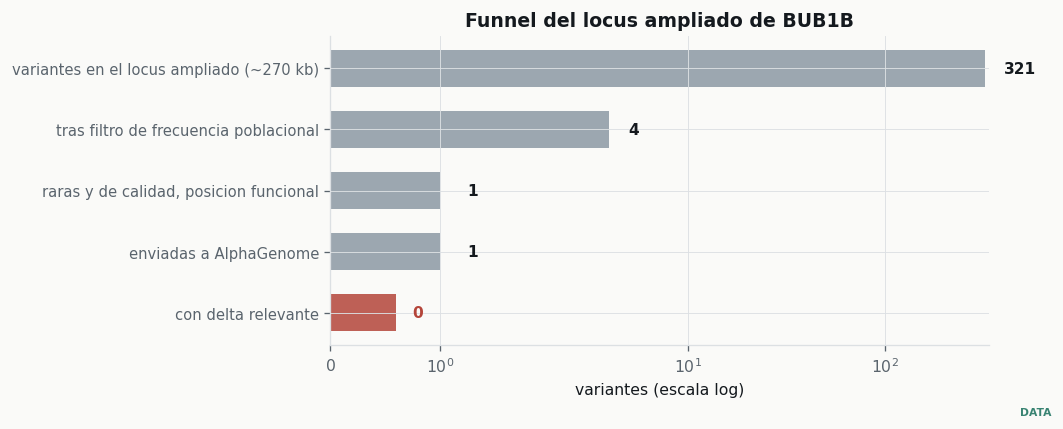

> **Figura principal 1 · el funnel del locus**  
> `EXP-008` · figure class `DATA`, figura cientifica · evidence origin `MEASURED+DERIVED`  
> *Que se observa.* de 321 variantes en 270 kb, una sola sobrevivio a frecuencia, calidad y posicion funcional: una intronica profunda ausente de gnomAD, sin rsID, PASS, heterocigota, a mas de 1 kb del borde de exon mas cercano.  
> **Alcance del resultado.** que no exista un segundo alelo. Este funnel solo cubre SNV e indel dentro de la ventana: no ve variantes estructurales, que son EXP-012 y estan bloqueadas.  
> procedencia: `docs/DECISIONS.md § Hidden Second Allele`

In [4]:
fig, ax = plt.subplots(figsize=(9.0, 3.6))
names = [s[0] for s in LOCUS][::-1]
vals = [s[1] for s in LOCUS][::-1]
mx = max(vals)
cols = [fl.DEAD if v == 0 else fl.FLOW for v in vals]
ax.barh(range(len(names)), [max(v, 0.6) for v in vals], color=cols, alpha=0.85, height=0.6)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9)
ax.set_xscale("symlog"); ax.set_xlabel("variantes (escala log)")
for i, v in enumerate(vals):
    ax.text(max(v, 0.6) * 1.25, i, str(v), va="center", fontsize=9.4, fontweight="bold",
            color=fl.DEAD if v == 0 else fl.INK)
ax.set_title("Funnel del locus ampliado de BUB1B")

fl.done(fig, "Figura principal 1 · el funnel del locus", "EXP-008", "MEASURED+DERIVED",
        "DATA",
        "de 321 variantes en 270 kb, una sola sobrevivio a frecuencia, calidad y posicion "
        "funcional: una intronica profunda ausente de gnomAD, sin rsID, PASS, heterocigota, "
        "a mas de 1 kb del borde de exon mas cercano.",
        "que no exista un segundo alelo. Este funnel solo cubre SNV e indel dentro de la "
        "ventana: no ve variantes estructurales, que son EXP-012 y estan bloqueadas.",
        prov="docs/DECISIONS.md § Hidden Second Allele")

## Resultado primario · AlphaGenome sobre el único candidato

Las pistas que se dibujan **se congelaron antes** de repetir la llamada, para que no se
pudieran elegir las más favorecedoras después de verlas. Y las reglas de dibujo también: REF y
ALT comparten escala Y, y el Δ va en su propio carril con el cero visible.

**Fue la única transmisión de un dato del paciente fuera de la máquina en todo el proyecto**,
prevista en `docs/03_ALPHAGENOME_ASSESSMENT.md` §7. Se envió la shortlist, nunca el VCF.

In [5]:
import glob
AG = glob.glob("work/alphagenome/chr*_A_G.json")[0]      # ruta no impresa: lleva coordenada
ag = json.load(io.open(AG, encoding="utf-8"))
mods = ag["modalities"]
print(f"  estado de la llamada: {ag.get('status')}  ·  ventana: {ag.get('window_bp'):,} pb")
print()
print(f"  {'modalidad':<22}{'pistas':>8}{'delta rel %':>14}{'delta local max':>18}")
for m in sorted(mods, key=lambda x: -abs(x["delta_rel"])):
    print(f"  {m['modalidad']:<22}{m['pistas']:>8}{m['delta_rel']:>14.3f}"
          f"{m['delta_local_max']:>18.4f}")
peor = max(abs(m["delta_rel"]) for m in mods)
spl = [m for m in mods if "splic" in m["modalidad"]]
print()
print(f"  mayor delta relativo de cualquier modalidad : {peor:.2f} %")
if spl:
    print(f"  delta LOCAL de junciones de splicing        : "
          f"{min(m['delta_local_max'] for m in spl):.4f}")

  estado de la llamada: PREDICTED  ·  ventana: 1,048,576 pb

  modalidad               pistas   delta rel %   delta local max
  rna_seq                    667         0.034            0.1562
  chip_tf                   1617         0.022           96.0000
  dnase                      305         0.019            0.7500
  chip_histone              1116         0.018           16.0000
  atac                       167         0.013            0.1875
  splice_site_usage          734         0.012            0.0039
  splice_sites                 4         0.008            0.0063
  splice_junctions           367         0.004            0.0000

  mayor delta relativo de cualquier modalidad : 0.03 %
  delta LOCAL de junciones de splicing        : 0.0000


### Figura principal 2 · navegador REF / ALT / Δ, pista a pista

La figura resumen agrega por modalidad. Esta **no agrega nada**: dibuja las nueve pistas
congeladas tal y como salieron del modelo, sobre un **eje genómico compartido**, con el modelo
del gen encima.

Dos reglas de dibujo, fijadas antes de mirar:

1. **REF y ALT comparten escala Y exacta** dentro de cada pista. Sin esto, cualquier diferencia
   puede fabricarse reescalando.
2. **El Δ va en su propio carril con el cero visible** y escala simétrica. Nunca superpuesto.

> El eje X es **desplazamiento respecto a la variante**, no coordenada absoluta.

In [6]:
AR = glob.glob("work/alphagenome/arrays_*.json")[0]
ar = json.load(io.open(AR, encoding="utf-8"))
TRK = ar["tracks"]
VPOS = ar["pos"]
FL = ar["flank_bp"]
print(f"  estado: {ar['status']}  ·  ventana: +/-{FL:,} pb  ·  pistas congeladas: {len(TRK)}")
for t in TRK:
    print(f"    {t['mod']:<20}{t['bp_per_bin']:>8.0f} pb/bin  {len(t['ref']):>6} bins   "
          f"{str(t['meta'])[:52]}")

from src.structure.transcript_model import fetch as fetch_tx
TX = fetch_tx()
EXW = [(e["start"] - VPOS, e["end"] - VPOS) for e in TX["exons"]
       if e["end"] > VPOS - FL and e["start"] < VPOS + FL]
print(f"  exones de {TX['transcript']} dentro de la ventana: {len(EXW)}")

  estado: PREDICTED  ·  ventana: +/-5,000 pb  ·  pistas congeladas: 9
    splice_sites               1 pb/bin   10000 bins   donor
    splice_site_usage          1 pb/bin   10000 bins   usage_CL:0000047 polyA plus RNA-seq · neuronal stem 
    splice_junctions         779 pb/bin      12 bins   junction_UBERON:0000473 gtex Testis polyA plus RNA-s
    chip_tf                  128 pb/bin      78 bins   CL:0002518 TF ChIP-seq CTCF · kidney epithelial cell
    chip_tf                  128 pb/bin      78 bins   CL:0002319 TF ChIP-seq RAD21 · neural cell
    rna_seq                    1 pb/bin   10000 bins   EFO:0002784 polyA plus RNA-seq · GM12878
    rna_seq                    1 pb/bin   10000 bins   EFO:0002067 polyA plus RNA-seq · K562
    atac                       1 pb/bin   10000 bins   CL:0000236 ATAC-seq · B cell
    dnase                      1 pb/bin   10000 bins   CL:0001059 DNase-seq · common myeloid progenitor, CD
  exones de ENST00000287598 dentro de la ventana: 5


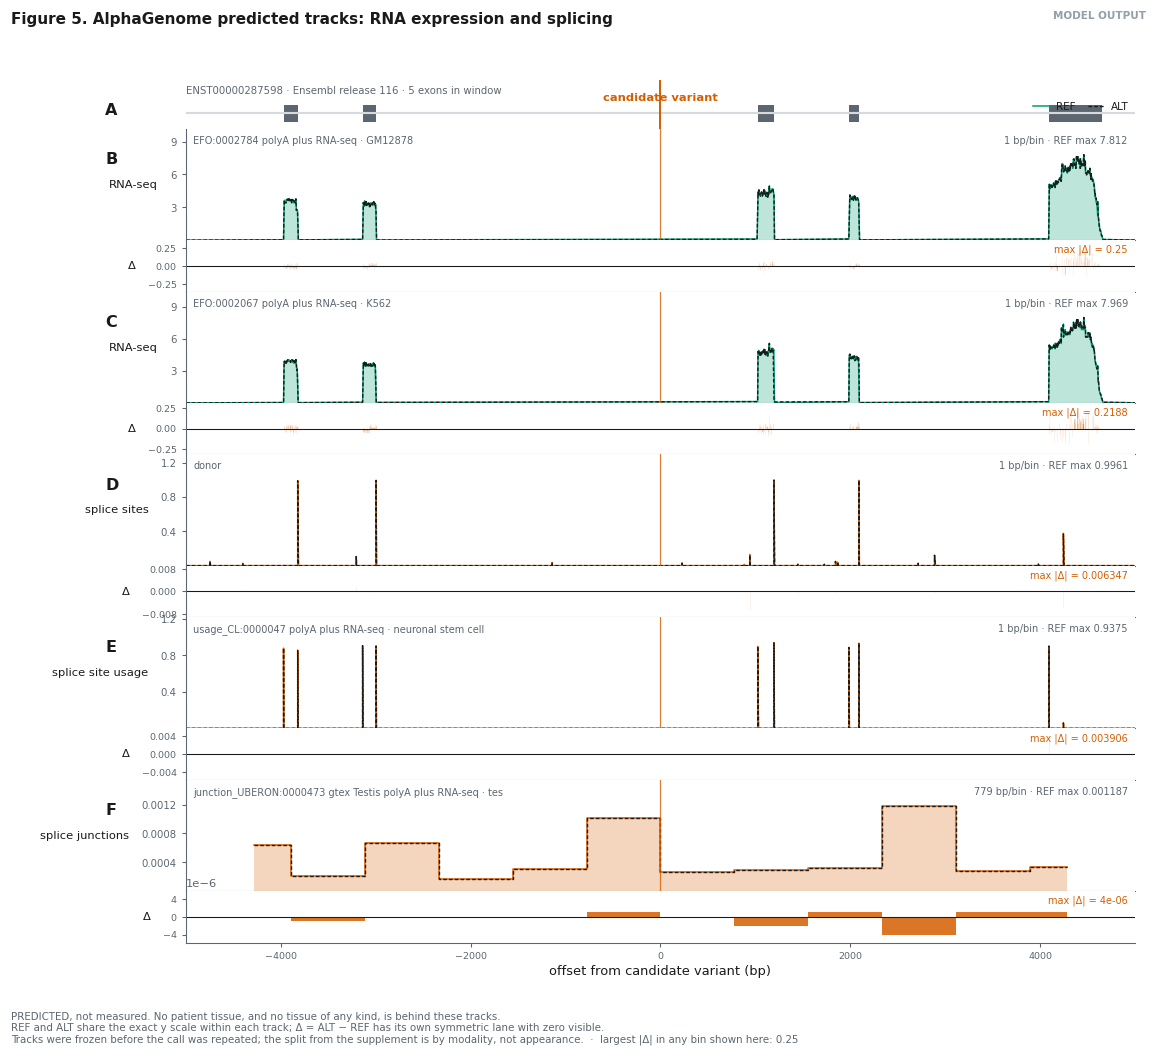

> **Figura principal 2. Navegador REF / ALT / delta: RNA expression and splicing**  
> `EXP-009` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED`  
> *Que se observa.* 5 de las nueve pistas congeladas sobre el mismo eje genomico, con el modelo del gen encima. REF y ALT comparten escala Y exacta dentro de cada pista y el delta va en su propio carril con el cero visible. El mayor |delta| de cualquier bin aqui es 0.25.  
> **Alcance del resultado.** que no exista un segundo alelo. Es una PREDICCION de un modelo sobre UN candidato SNV/indel, no una medida y no un barrido. Estas pistas NO son datos medidos del paciente ni de ningun tejido suyo.  
> datos: `work/alphagenome/arrays_*.json · pistas congeladas antes de repetir la llamada; el reparto entre figura y suplemento es por MODALIDAD` · libreria: `matplotlib` · procedencia: `figures/pub/fig04_alphagenome_rna_splicing.svg + .png 300 dpi`

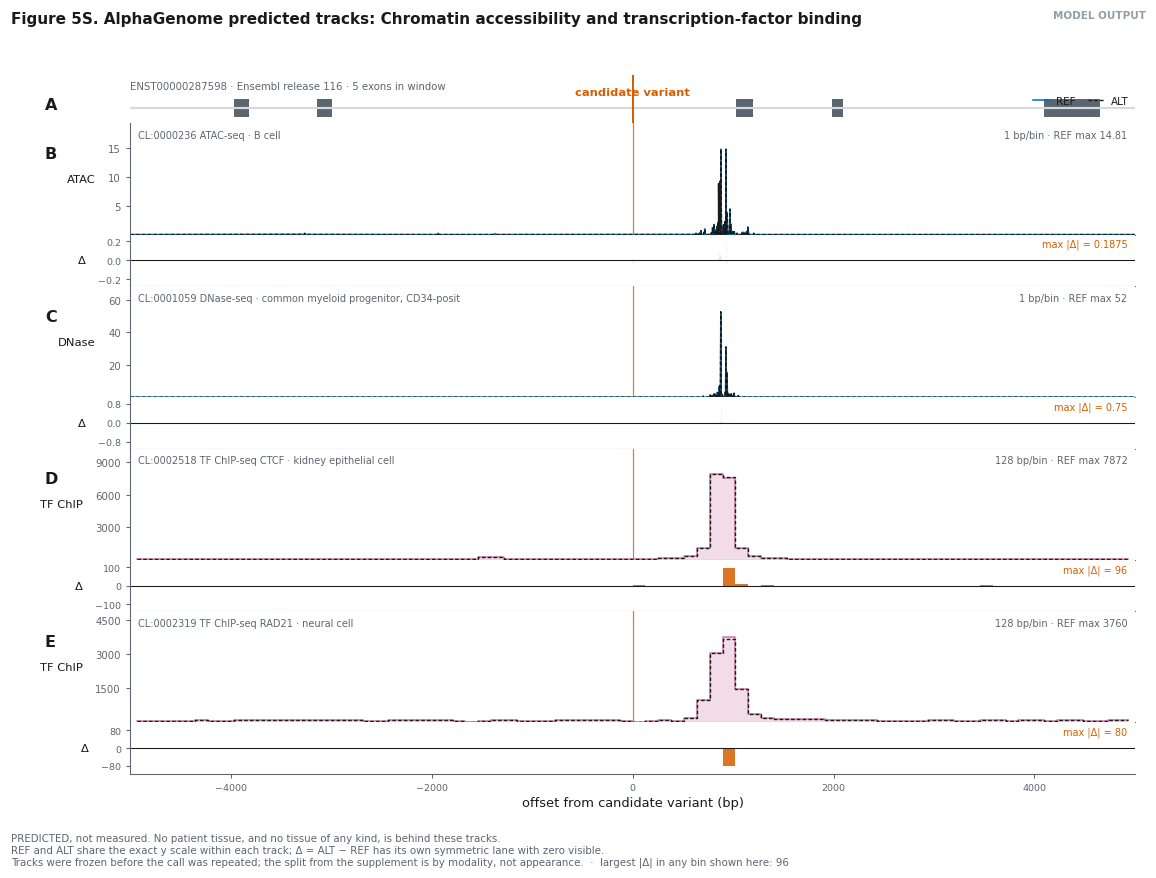

> **Figura suplementaria 2S. Navegador REF / ALT / delta: Chromatin accessibility and transcription-factor binding**  
> `EXP-009` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED`  
> *Que se observa.* 4 de las nueve pistas congeladas sobre el mismo eje genomico, con el modelo del gen encima. REF y ALT comparten escala Y exacta dentro de cada pista y el delta va en su propio carril con el cero visible. El mayor |delta| de cualquier bin aqui es 96.  
> **Alcance del resultado.** que no exista un segundo alelo. Es una PREDICCION de un modelo sobre UN candidato SNV/indel, no una medida y no un barrido. Estas pistas NO son datos medidos del paciente ni de ningun tejido suyo.  
> datos: `work/alphagenome/arrays_*.json · pistas congeladas antes de repetir la llamada; el reparto entre figura y suplemento es por MODALIDAD` · libreria: `matplotlib` · procedencia: `figures/pub/fig04S_alphagenome_accessibility_tf.svg + .png 300 dpi`

In [7]:
from src.figures import fig04_tracks as FT

_figs, _ar = FT.load_and_build()
for _which, _slug, _tag in (("main", "fig04_alphagenome_rna_splicing", "principal 2"),
                            ("supp", "fig04S_alphagenome_accessibility_tf", "suplementaria 2S")):
    _f, _st = _figs[_which]
    fl.pub(_f, f"Figura {_tag}. Navegador REF / ALT / delta: {FT.GROUPS[_which]['title']}",
           "EXP-009", "PREDICTED", "MODEL_OUTPUT",
           f"{_st['n_tracks']} de las nueve pistas congeladas sobre el mismo eje genomico, "
           f"con el modelo del gen encima. REF y ALT comparten escala Y exacta dentro de "
           f"cada pista y el delta va en su propio carril con el cero visible. El mayor "
           f"|delta| de cualquier bin aqui es {_st['max_abs_delta']:.4g}.",
           "que no exista un segundo alelo. Es una PREDICCION de un modelo sobre UN "
           "candidato SNV/indel, no una medida y no un barrido. Estas pistas NO son datos "
           "medidos del paciente ni de ningun tejido suyo.",
           source="work/alphagenome/arrays_*.json · pistas congeladas antes de repetir la "
                  "llamada; el reparto entre figura y suplemento es por MODALIDAD",
           lib="matplotlib", slug=_slug)

### Caracterización post-congelación · mutagénesis in silico y mapas de contacto

**Esto no es evidencia nueva ni reabre nada.** Cierra una pregunta que el navegador de arriba
deja abierta: *¿el modelo responde a cambios de secuencia en este vecindario, y el candidato
cae donde responde?* Y una segunda: *¿la arquitectura de contactos predicha cambia con ALT?*

Las dos salidas se produjeron **sobre el mismo candidato congelado**, con un manifest escrito
y sellado con `sha256` **antes** de la primera llamada al modelo. Ese manifest fija ventana,
contexto, scorers, ontología, biosample y la regla de lectura. Los runners rechazan ejecutarse
si el manifest cambia; `src/verify.py` comprueba que las corridas citan ese mismo hash.

- **ISM:** 256 posiciones × 3 alternativas = 768 sustituciones **sintéticas** de la referencia,
  puntuadas con dos lecturas que replican el reparto por modalidad del bloque: *splice sites*
  (primaria, la modalidad que decidió) y *DNase* sobre la pista ya congelada (secundaria).
  Regla predeclarada: hay «sensibilidad local concentrada» si el candidato queda en el 5 %
  superior de posiciones por |efecto|. Chequeo de contexto a 100 kb, sólo reportado.
- **Contactos:** REF, ALT y ALT − REF a 2 048 pb en un biosample elegido por criterio antes de
  predecir (fibroblasto primario, el tipo celular de los estudios funcionales de MVA). Los 28
  biosamples disponibles se puntúan con el scorer oficial como contexto, nunca para elegir.

Ninguna de las dos puede subir la VUS, mover el ranking de Track 1 ni convertirse en evidencia
del paciente. Un negativo aquí es tan reportable como un positivo, y es lo que salió.

In [8]:
MI = json.load(io.open("work/alphagenome/ism/metadata.json", encoding="utf-8"))
MC = json.load(io.open("work/alphagenome/contacts/metadata.json", encoding="utf-8"))
MAN = io.open("work/alphagenome/run_manifest.json.sha256").read().strip()
assert MI["manifest_sha256"] == MC["manifest_sha256"] == MAN, "corridas sobre manifests distintos"
print(f"  manifest congelado : sha256 {MAN[:12]}...  (citado por las dos corridas)")
print(f"  ISM                : {MI['primary']['n_variants']} sustituciones sinteticas, "
      f"ventana {MI['primary']['ism_window_bp']} pb, contexto {MI['primary']['sequence_context_bp']:,} pb")
for _r, _i in MI["primary"]["roles"].items():
    _k = _i["ranks"]
    print(f"    {_r:<9} {_i['scorer']['output']:<13} candidato: posicion {_k['candidate_position_rank_of_L']:>3} de "
          f"{MI['primary']['ism_window_bp']} · sustitucion {_k['candidate_substitution_rank_of_all']:>3} de "
          f"{3 * MI['primary']['ism_window_bp']} · maximo de la ventana en {_k['window_argmax_offset']:+d} pb")
_ip = MI["interpretation"]
print(f"    lectura predeclarada: {_ip['reading']}")
print(f"    contexto r(16 kb, 100 kb): " + ", ".join(f"{k} {v:.2f}" for k, v in _ip["context_pearson_r"].items()))
_ic = MC["interpretation"]
print(f"  contactos          : {MC['biosample_name']} ({MC['ontology_curie']}), "
      f"{MC['n_bins']}x{MC['n_bins']} bins de {MC['output_resolution_bp']} pb")
print(f"    max |ALT-REF| / max REF = {100 * _ic['ratio']:.2f} % (umbral predeclarado 5 %) -> "
      f"{_ic['reading']}")
print(f"    robustez: la pista predeclarada ocupa el puesto {MC['robustness']['chosen_rank_of_n']} de "
      f"{MC['robustness']['n_tracks']} con el scorer oficial")

  manifest congelado : sha256 2709ed86c2b3...  (citado por las dos corridas)
  ISM                : 768 sustituciones sinteticas, ventana 256 pb, contexto 16,384 pb
    PRIMARY   SPLICE_SITES  candidato: posicion  62 de 256 · sustitucion 251 de 768 · maximo de la ventana en +125 pb
    SECONDARY DNASE         candidato: posicion 168 de 256 · sustitucion 268 de 768 · maximo de la ventana en -109 pb
    lectura predeclarada: no compelling local ISM sensitivity under the pre-specified readout
    contexto r(16 kb, 100 kb): PRIMARY 0.95, SECONDARY 0.98
  contactos          : skin fibroblast (CL:0002620), 512x512 bins de 2048 pb
    max |ALT-REF| / max REF = 1.09 % (umbral predeclarado 5 %) -> no compelling predicted contact effect
    robustez: la pista predeclarada ocupa el puesto 8 de 28 con el scorer oficial


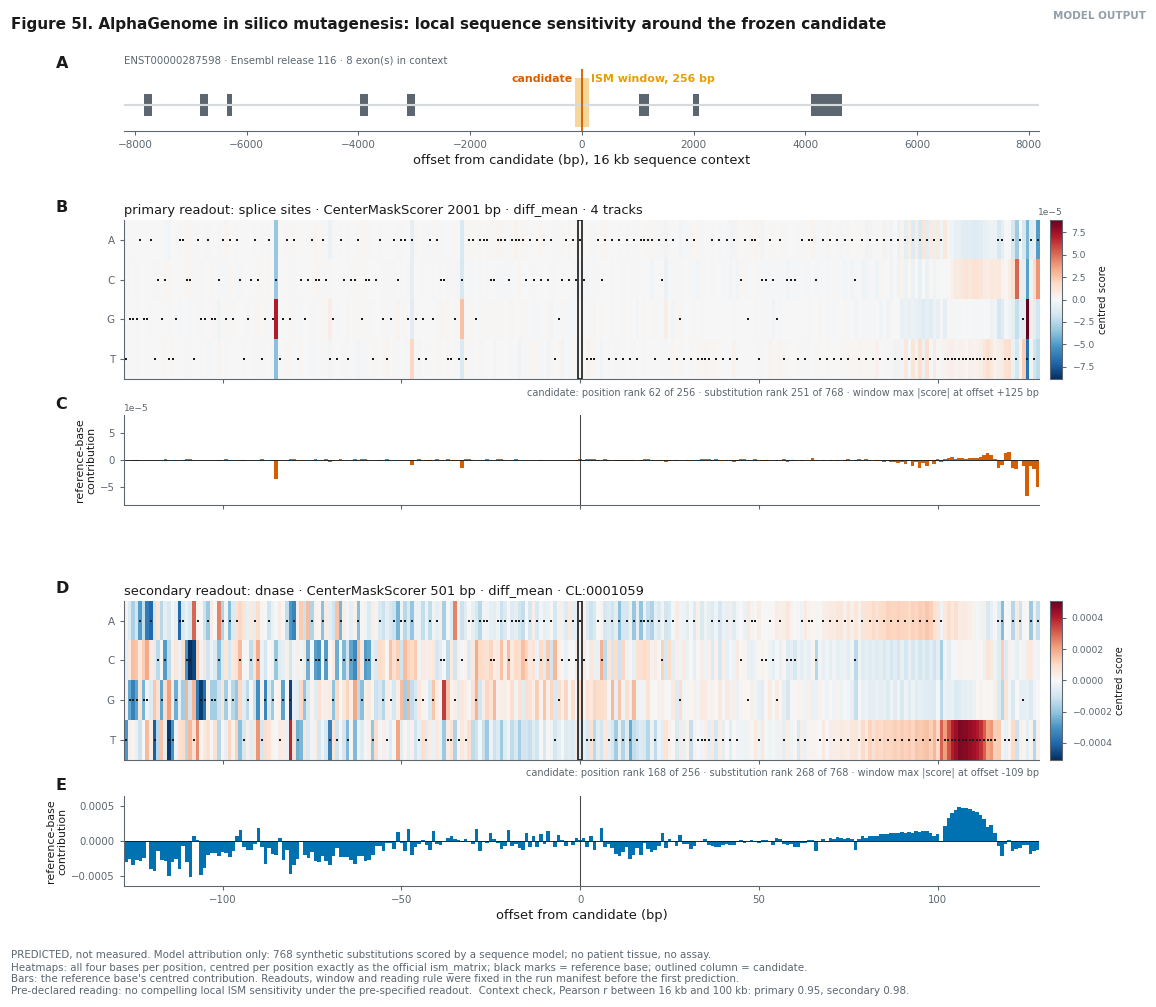

> **Figura principal 2I. Mutagenesis in silico: sensibilidad local del modelo alrededor del candidato**  
> `EXP-023` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED`  
> *Que se observa.* 768 sustituciones sinteticas puntuadas con dos lecturas predeclaradas. Bajo la primaria (splice sites) el candidato ocupa la posicion 62 de 256 por |efecto| y la sustitucion 251 de 768; bajo la secundaria (DNase) la posicion 168. El maximo de la ventana esta a +125 pb (primaria) y -109 pb (secundaria). Lectura predeclarada: no compelling local ISM sensitivity under the pre-specified readout. El chequeo a 100 kb reproduce la matriz (r = 0.95).  
> **Alcance del resultado.** que la region sea funcional o no funcional, que la variante sea patogenica o benigna, ni ningun mecanismo regulador en el paciente. Es ATRIBUCION de un modelo bajo un scorer y un contexto concretos: informa la caracterizacion del negativo ya congelado y no cambia ninguna clasificacion ni ranking.  
> datos: `work/alphagenome/ism/*.json.gz + metadata.json · manifest sellado antes de la llamada` · libreria: `matplotlib` · procedencia: `figures/pub/fig04I_alphagenome_ism.svg + .png 300 dpi`

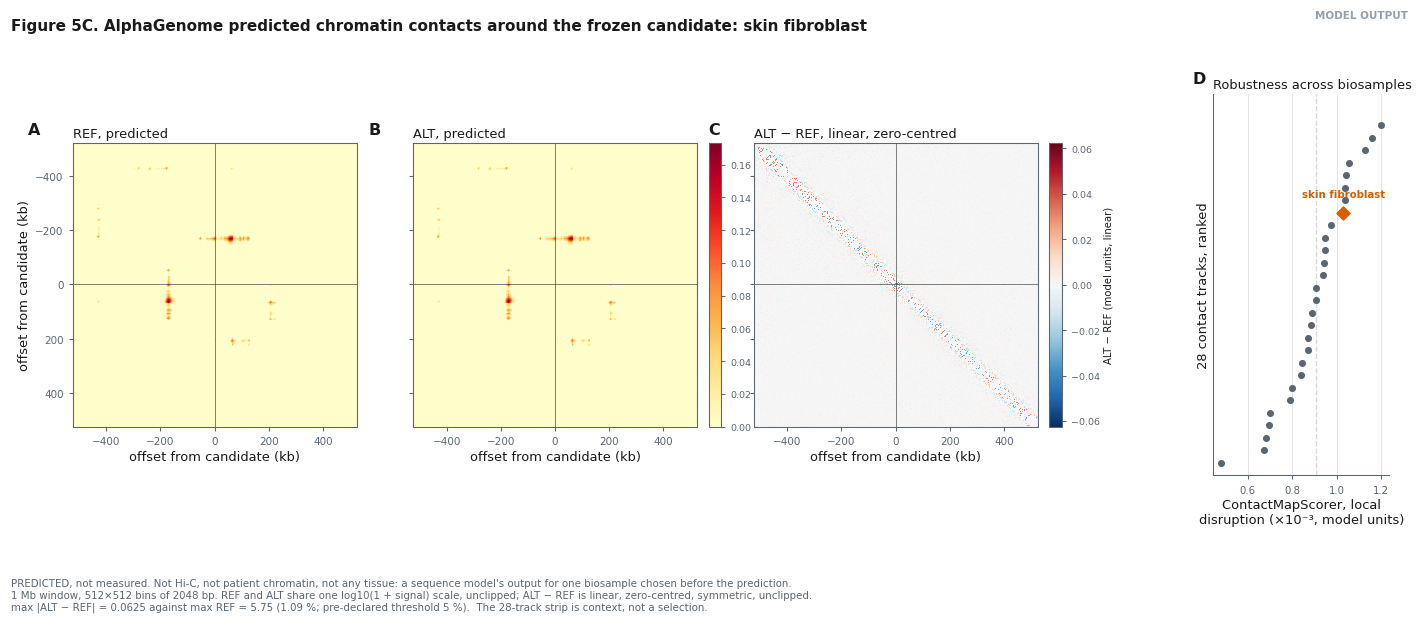

> **Figura suplementaria 2C. Mapas de contacto predichos: REF, ALT y ALT - REF**  
> `EXP-023` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED`  
> *Que se observa.* ventana de 1 Mb a 2048 pb en el biosample predeclarado (skin fibroblast). REF y ALT comparten escala y son indistinguibles a ojo; ALT - REF alcanza el 1.09 % del maximo de REF, por debajo del 5 % fijado antes de predecir. La pista ocupa el puesto 8 de 28 con el scorer oficial de disrupcion local.  
> **Alcance del resultado.** que la cromatina del paciente sea asi, que exista o no un bucle enhancer-promotor, ni que la expresion del gen cambie. No es Hi-C y no es un tejido: es la salida de un modelo para un biosample. Una diferencia visible motivaria una hipotesis; no la demostraria.  
> datos: `work/alphagenome/contacts/*.json.gz + robustness_scores.json + metadata.json` · libreria: `matplotlib` · procedencia: `figures/pub/fig04C_alphagenome_contact_maps.svg + .png 300 dpi`

In [9]:
from src.figures import fig04_ism as FI
from src.figures import fig04_contacts as FC

_f, _st = FI.load_and_build()
fl.pub(_f, "Figura principal 2I. Mutagenesis in silico: sensibilidad local del modelo alrededor del candidato",
       "EXP-023", "PREDICTED", "MODEL_OUTPUT",
       f"768 sustituciones sinteticas puntuadas con dos lecturas predeclaradas. Bajo la primaria "
       f"(splice sites) el candidato ocupa la posicion {_st['readouts']['PRIMARY']['rank_pos']} de "
       f"{_st['L']} por |efecto| y la sustitucion {_st['readouts']['PRIMARY']['rank_sub']} de "
       f"{3 * _st['L']}; bajo la secundaria (DNase) la posicion {_st['readouts']['SECONDARY']['rank_pos']}. "
       f"El maximo de la ventana esta a {_st['readouts']['PRIMARY']['argmax_offset']:+d} pb "
       f"(primaria) y {_st['readouts']['SECONDARY']['argmax_offset']:+d} pb (secundaria). "
       f"Lectura predeclarada: {_st['reading']}. "
       f"El chequeo a 100 kb reproduce la matriz (r = {_st['context_r']['PRIMARY']:.2f}).",
       "que la region sea funcional o no funcional, que la variante sea patogenica o benigna, "
       "ni ningun mecanismo regulador en el paciente. Es ATRIBUCION de un modelo bajo un scorer y "
       "un contexto concretos: informa la caracterizacion del negativo ya congelado y no cambia "
       "ninguna clasificacion ni ranking.",
       source="work/alphagenome/ism/*.json.gz + metadata.json · manifest sellado antes de la llamada",
       lib="matplotlib", slug="fig04I_alphagenome_ism")

_f, _st = FC.load_and_build()
fl.pub(_f, "Figura suplementaria 2C. Mapas de contacto predichos: REF, ALT y ALT - REF",
       "EXP-023", "PREDICTED", "MODEL_OUTPUT",
       f"ventana de 1 Mb a {MC['output_resolution_bp']} pb en el biosample predeclarado "
       f"({MC['biosample_name']}). REF y ALT comparten escala y son indistinguibles a ojo; "
       f"ALT - REF alcanza el {100 * _st['ratio']:.2f} % del maximo de REF, por debajo del 5 % "
       f"fijado antes de predecir. La pista ocupa el puesto {_st['chosen_rank']} de "
       f"{_st['n_tracks']} con el scorer oficial de disrupcion local.",
       "que la cromatina del paciente sea asi, que exista o no un bucle enhancer-promotor, ni que "
       "la expresion del gen cambie. No es Hi-C y no es un tejido: es la salida de un modelo "
       "para un biosample. Una diferencia visible motivaria una hipotesis; no la demostraria.",
       source="work/alphagenome/contacts/*.json.gz + robustness_scores.json + metadata.json",
       lib="matplotlib", slug="fig04C_alphagenome_contact_maps")

### La figura resumen, que fue la que cerró la rama

### Control de robustez · se revisaron las pistas individuales

Para descartar que un efecto específico de tejido se estuviera diluyendo en el agregado:

- **El top por cambio relativo es ruido.** Las líneas base locales son ~0,0001–0,005; un 5 %
  sobre cero es división por un número minúsculo.
- **El top por cambio absoluto** son pistas de CTCF y RAD21, con cambios del 1,2–2,3 % sobre
  líneas base de 1 400–7 900. Nada funcionalmente interpretable.
- **Sin coherencia biológica**: los tejidos del top son un surtido disperso. No hay señal renal
  ni hematopoyética.

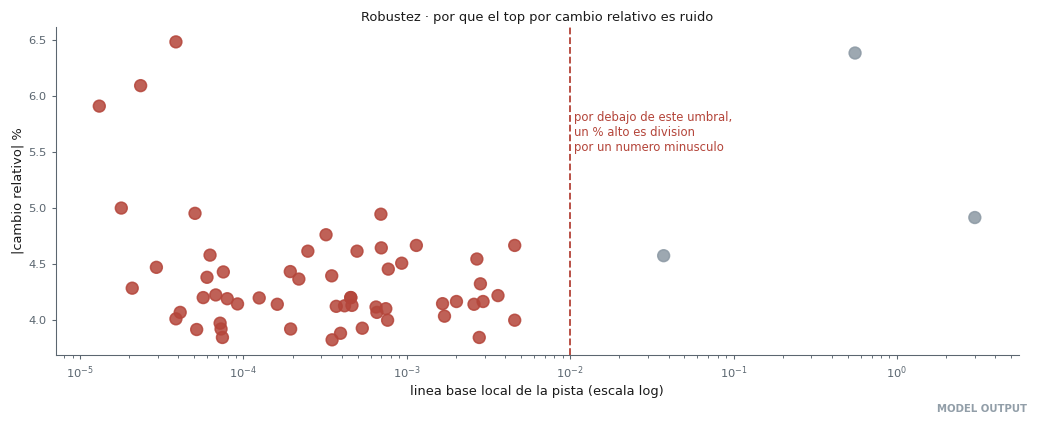

> **Figura de robustez · el % relativo enganya cuando la base es cero**  
> `EXP-009` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `PREDICTED`  
> *Que se observa.* cada punto es una de las pistas con mayor cambio relativo. Las que producen porcentajes grandes tienen lineas base proximas a cero: el porcentaje es un artefacto de la division, no senal.  
> **Alcance del resultado.** que no exista efecto en ningun tejido. Es un argumento sobre la METRICA, no una busqueda exhaustiva por tejido.  
> procedencia: `work/alphagenome/*_tracks.json`

In [10]:
TR = glob.glob("work/alphagenome/chr*_tracks.json")[0]
tr = json.load(io.open(TR, encoding="utf-8"))
top = [t for t in tr.get("top_rel", []) if t.get("rloc")]
if top:
    fig, ax = plt.subplots(figsize=(9.4, 3.8))
    rels = [abs(t["rel"]) * 100 for t in top]
    bases = [t["rloc"] for t in top]
    ax.scatter(bases, rels, s=60, c=[fl.DEAD if b < 0.01 else fl.FLOW for b in bases],
               alpha=0.85)
    ax.set_xscale("log"); ax.set_xlabel("linea base local de la pista (escala log)")
    ax.set_ylabel("|cambio relativo| %")
    ax.axvline(0.01, color=fl.DEAD, ls="--", lw=1.2)
    ax.text(0.0105, max(rels) * 0.85, "por debajo de este umbral,\nun % alto es division\npor "
            "un numero minusculo", fontsize=7.6, color=fl.DEAD)
    ax.set_title("Robustez · por que el top por cambio relativo es ruido")
    fl.done(fig, "Figura de robustez · el % relativo enganya cuando la base es cero",
            "EXP-009", "PREDICTED", "MODEL_OUTPUT",
            "cada punto es una de las pistas con mayor cambio relativo. Las que producen "
            "porcentajes grandes tienen lineas base proximas a cero: el porcentaje es un "
            "artefacto de la division, no senal.",
            "que no exista efecto en ningun tejido. Es un argumento sobre la METRICA, no una "
            "busqueda exhaustiva por tejido.",
            prov="work/alphagenome/*_tracks.json")
else:
    print("  sin pistas individuales en el fichero; el argumento queda en el texto")

## Decisión

| Rama | Estado |
|---|---|
| **Segundo alelo SNV/indel regulador** | **NEGATIVE** en el alcance evaluado |
| **Segundo alelo estructural (SV/CNV)** | **BLOCKED**, falta BAM/CRAM de profundidad completa |

**La formulación exacta:** *No candidate survived population filtering plus global and
track-level AlphaGenome interrogation.*

**No:** «AlphaGenome demostró que no existe un segundo alelo».

### Sobre la CNV grande

Desde la profundidad y la heterocigosidad del VCF: la región no muestra pérdida de
heterocigosidad ni caída de profundidad, se observa lo contrario. Pero **la profundidad del
VCF no está normalizada para llamar número de copia**, así que lo defendible es *no evidence
for a large heterozygous deletion*, no «CNV descartada».

**Sigue sin resolverse:** CNV pequeñas que quepan entre variantes, eventos equilibrados que no
cambian número de copia, inserciones, y todo lo local a un punto de rotura.

### Falsificador

Con el BAM/CRAM de los cuatro carriles se llamarían variantes estructurales usando pares
discordantes y *split reads*.
**Prohibido cerrar un negativo estructural con L001**: un carril a ~13× es piloto, no ausencia.

### Siguiente experimento

`05_RESIDUAL_PHENOTYPE`. Si el segundo alelo no aparece, ¿y si parte del fenotipo no es de
`BUB1B`?